# Task analysis: reconstruction error and sample reconstructions

This notebook is the required read of the MNIST autoencoder run. The design lives in `notebooks/engineering.ipynb`. The numbers and figures come from `make all`.

Two questions:

1. How does validation reconstruction MSE change as the latent size grows?
2. What do the reconstructions look like for the latent size Optuna kept?

Compression ratio is `784 / latent_dim`. Reconstruction MSE on pixels in [-1, 1] is the compression error. A shorter code throws away more of the digit, so the error should be highest at latent size 2 and lower once the code is long enough to hold stroke shape.

Run `uv sync` and `make all` first. Artifact paths use the repository root, including when the kernel starts in `notebooks/`.


In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
from IPython.display import display

from mnist_ae_compression.config import MODELING_CONTRACT_PATH, PIXEL_MEAN, PIXEL_STD, project_root
from mnist_ae_compression.model import Autoencoder
from mnist_contracts.model_contract import ModelingContract

ROOT = project_root()
STUDY = ROOT / "reports" / "mnist_ae_compression" / "mnist_ae.db"
MODEL = ROOT / "models" / "mnist_ae_compression" / "mnist_ae.pt"
PIXELS = ROOT / "data" / "mnist_ae_compression" / "pixels.npy"
TABLE = ROOT / "data" / "mnist_ae_compression" / "images.parquet"
SPLIT = ROOT / "data" / "mnist_ae_compression" / "split.json"
TRAIN_METRICS = ROOT / "reports" / "mnist_ae_compression" / "evaluation_train.json"
TEST_METRICS = ROOT / "reports" / "mnist_ae_compression" / "evaluation_test.json"

missing = [path for path in (STUDY, MODEL, PIXELS, TABLE, SPLIT, TRAIN_METRICS, TEST_METRICS) if not path.is_file()]
if missing:
    joined = ", ".join(str(path.relative_to(ROOT)) for path in missing)
    raise FileNotFoundError(f"Run `make all` from the repo root first. Missing: {joined}")


## Reconstruction error against latent size

Each completed Optuna trial contributes its validation MSE. Trials that share a latent size are averaged. The other settings on the enqueued trials are fixed, so this curve is the bottleneck comparison.


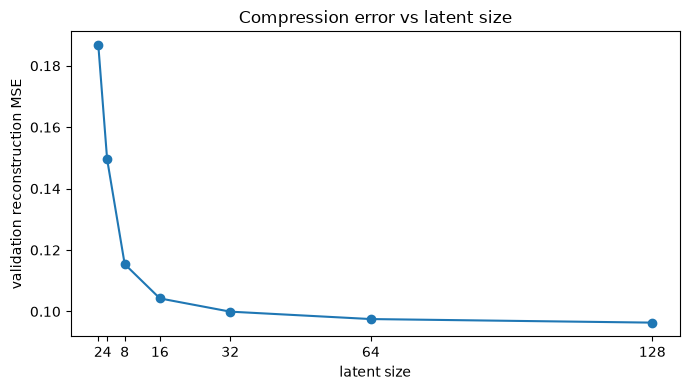

latent   2  compression   392.00x  val MSE 0.1867
latent   4  compression   196.00x  val MSE 0.1496
latent   8  compression    98.00x  val MSE 0.1154
latent  16  compression    49.00x  val MSE 0.1042
latent  32  compression    24.50x  val MSE 0.0999
latent  64  compression    12.25x  val MSE 0.0975
latent 128  compression     6.12x  val MSE 0.0964


In [3]:
study = optuna.load_study(study_name="mnist_ae", storage="sqlite:///" + STUDY.resolve().as_posix())
grouped: dict[int, list[float]] = {}
for trial in study.trials:
    if trial.state != optuna.trial.TrialState.COMPLETE or trial.value is None:
        continue
    if "latent_dim" not in trial.params:
        continue
    grouped.setdefault(int(trial.params["latent_dim"]), []).append(float(trial.value))

sizes = sorted(grouped)
means = [float(np.mean(grouped[size])) for size in sizes]
ratios = [784 / size for size in sizes]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sizes, means, marker="o")
ax.set_xlabel("latent size")
ax.set_ylabel("validation reconstruction MSE")
ax.set_xticks(sizes)
ax.set_title("Compression error vs latent size")
fig.tight_layout()
display(fig)
plt.close(fig)

for size, score, ratio in zip(sizes, means, ratios, strict=True):
    print(f"latent {size:3d}  compression {ratio:8.2f}x  val MSE {score:.4f}")


## Held-out scores for the chosen code

Stage 05 fits the latent size with the lowest validation MSE. Stage 06 scores that checkpoint on the official train and test splits. The test split was not used to pick the size.


In [4]:
train_metrics = json.loads(TRAIN_METRICS.read_text(encoding="utf-8"))
test_metrics = json.loads(TEST_METRICS.read_text(encoding="utf-8"))
print("train", json.dumps(train_metrics, indent=2))
print("test", json.dumps(test_metrics, indent=2))
print(
    f"chosen latent {test_metrics['latent_dim']}, "
    f"compression {test_metrics['compression_ratio']:.2f}x, "
    f"test MSE {test_metrics['mse']:.4f}"
)


train {
  "mse": 0.04136882082790463,
  "mae": 0.0772583126032695,
  "compression_ratio": 6.125,
  "latent_dim": 128,
  "n_train": 60000,
  "n_test": 10000
}
test {
  "mse": 0.04135477258773978,
  "mae": 0.07707968347625063,
  "compression_ratio": 6.125,
  "latent_dim": 128,
  "n_train": 60000,
  "n_test": 10000
}
chosen latent 128, compression 6.12x, test MSE 0.0414


## Sample reconstructions

The top row is the original digit. The bottom row is the autoencoder's reconstruction of that same digit. Pixels are mapped back from [-1, 1] with the stage-02 scale, `x * 0.5 + 0.5`, and clipped to [0, 1].


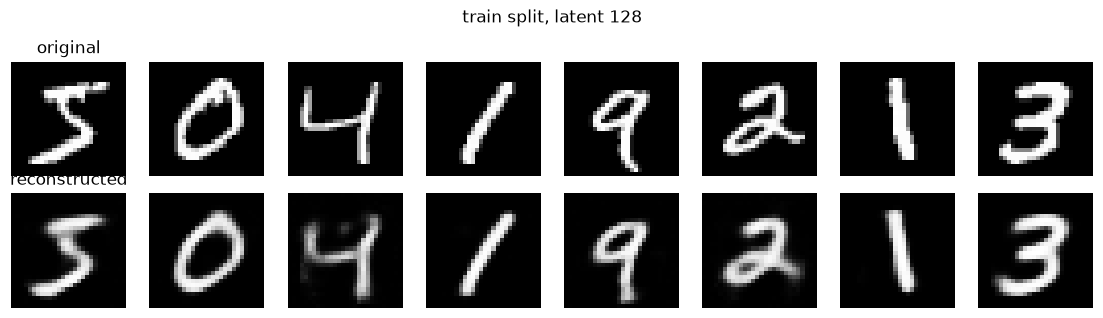

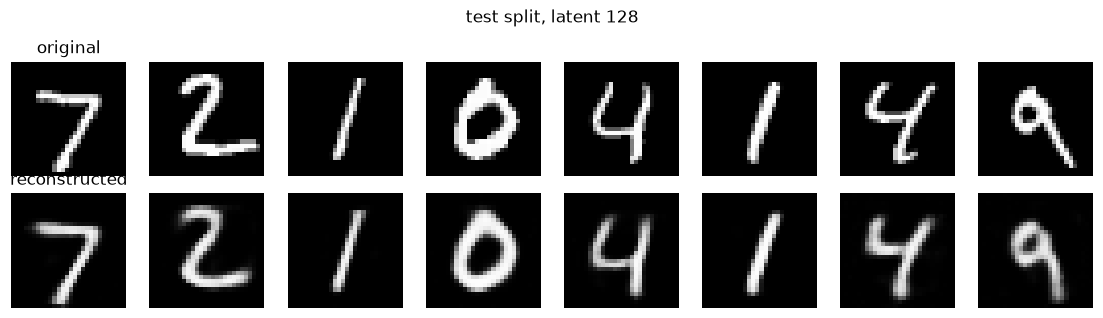

In [5]:
contract = ModelingContract.load(MODELING_CONTRACT_PATH)
batch, pixels = contract.read(TABLE, PIXELS)
split = json.loads(SPLIT.read_text(encoding="utf-8"))
bundle = Autoencoder.load(MODEL)
model = bundle["model"]
hparams = bundle["hparams"]
batch_size = int(hparams["batch_size"])


def show_split(name: str, indices: list[int], n: int = 8) -> None:
    rows = contract.feature_matrix(pixels, indices[:n])
    restored = model.reconstruct(rows, batch_size)
    original = np.clip(rows[:, 0] * PIXEL_STD + PIXEL_MEAN, 0, 1)
    rebuilt = np.clip(restored[:, 0] * PIXEL_STD + PIXEL_MEAN, 0, 1)
    fig, axes = plt.subplots(2, len(rows), figsize=(1.4 * len(rows), 3.2), squeeze=False)
    for index in range(len(rows)):
        axes[0, index].imshow(original[index], cmap="gray", vmin=0, vmax=1)
        axes[1, index].imshow(rebuilt[index], cmap="gray", vmin=0, vmax=1)
        axes[0, index].axis("off")
        axes[1, index].axis("off")
    axes[0, 0].set_title("original")
    axes[1, 0].set_title("reconstructed")
    fig.suptitle(f"{name} split, latent {hparams['latent_dim']}")
    fig.tight_layout()
    display(fig)
    plt.close(fig)


show_split("train", split["train_idx"])
show_split("test", split["test_idx"])


## How to read the comparison

A latent size of 2 is a 392× compression of the 784-pixel image. The reconstruction is usually a blurry class average: the digit class may survive, the stroke does not. Sizes 16 and 32 are where MNIST digits usually become recognizable, because a code of that length can store thickness and slant. Sizes 64 and 128 approach the input and the MSE drop flattens; extra coordinates buy less visible detail.

Use the test MSE, not the train MSE, when quoting a single error. The latent-size curve is the validation MSE from the train split, which is the quantity Optuna minimized. The two reconstruction grids are the same checkpoint, so a gap between them is generalization of that code, not a second search.
